In [7]:
import pandas as pd
df = pd.read_csv("ai_resume_screening.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded successfully!
Shape: (30000, 7)
Columns: ['years_experience', 'skills_match_score', 'education_level', 'project_count', 'resume_length', 'github_activity', 'shortlisted']


In [8]:
print(df.info()) 

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   years_experience    30000 non-null  int64  
 1   skills_match_score  30000 non-null  float64
 2   education_level     30000 non-null  str    
 3   project_count       30000 non-null  int64  
 4   resume_length       30000 non-null  int64  
 5   github_activity     30000 non-null  int64  
 6   shortlisted         30000 non-null  str    
dtypes: float64(1), int64(4), str(2)
memory usage: 1.9 MB
None


In [9]:
print(df.isnull().sum())

years_experience      0
skills_match_score    0
education_level       0
project_count         0
resume_length         0
github_activity       0
shortlisted           0
dtype: int64


In [10]:
print(df["shortlisted"].value_counts())

shortlisted
Yes    20966
No      9034
Name: count, dtype: int64


In [11]:
print(df["education_level"].value_counts())

education_level
Bachelors      13461
Masters        10524
PhD             3024
High School     2991
Name: count, dtype: int64


In [12]:
X = df.drop("shortlisted", axis=1)
y = df["shortlisted"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.unique())

Features:
['years_experience', 'skills_match_score', 'education_level', 'project_count', 'resume_length', 'github_activity']

Target:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


In [13]:
from sklearn.preprocessing import LabelEncoder

education_encoder = LabelEncoder()
target_encoder = LabelEncoder()

X["education_level"] = education_encoder.fit_transform(X["education_level"])
y = target_encoder.fit_transform(y)

print(X.head())
print("\nTarget values:", y[:10])

   years_experience  skills_match_score  education_level  project_count  \
0                 6                84.7                0              7   
1                 3                59.1                2              5   
2                12               100.0                2             12   
3                14                66.8                1              8   
4                10                99.6                0             10   

   resume_length  github_activity  
0            234              158  
1            502               77  
2            753              381  
3            529              407  
4            754              331  

Target values: [0 0 1 1 1 1 1 0 1 1]


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24000, 6)
Testing data: (6000, 6)


In [15]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [16]:
y_pred = model.predict(X_test)

print("Predictions completed!")
print(y_pred[:20])

Predictions completed!
[1 0 0 0 1 1 1 1 0 1 0 1 1 1 1 0 1 0 1 1]


In [17]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8995

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.82      0.83      1807
           1       0.92      0.94      0.93      4193

    accuracy                           0.90      6000
   macro avg       0.88      0.88      0.88      6000
weighted avg       0.90      0.90      0.90      6000



[[1475  332]
 [ 271 3922]]


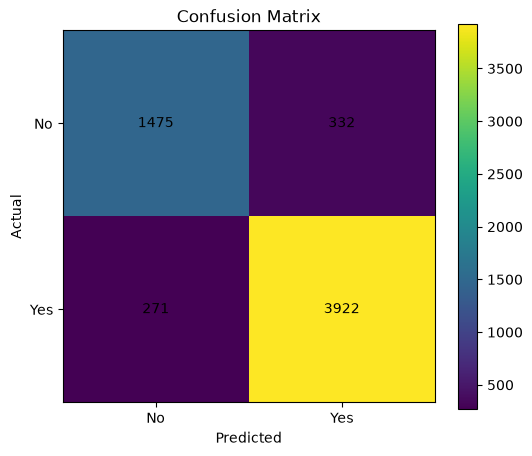

In [18]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xticks([0, 1], ["No", "Yes"])
plt.yticks([0, 1], ["No", "Yes"])

plt.show()

In [19]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

years_experience      0.286780
github_activity       0.238132
project_count         0.162044
skills_match_score    0.155863
resume_length         0.124049
education_level       0.033132
dtype: float64


In [20]:
def predict_candidate(experience, skills_score, education,
                      projects, resume_length, github_activity):

    education_code = education_encoder.transform([education])[0]

    candidate = pd.DataFrame([[
        experience,
        skills_score,
        education_code,
        projects,
        resume_length,
        github_activity
    ]], columns=X.columns)

    prediction = model.predict(candidate)[0]

    if prediction == 1:
        return "Shortlisted"
    else:
        return "Not Shortlisted"

In [15]:
result = predict_candidate(
    experience=3,
    skills_score=85,
    education="Masters",
    projects=5,
    resume_length=500,
    github_activity=100
)

print("Candidate Result:", result)

Candidate Result: Not Shortlisted


In [21]:
def predict_candidate_with_score(experience, skills_score, education,
                                 projects, resume_length, github_activity):

    education_code = education_encoder.transform([education])[0]

    candidate = pd.DataFrame([[
        experience,
        skills_score,
        education_code,
        projects,
        resume_length,
        github_activity
    ]], columns=X.columns)

    prediction = model.predict(candidate)[0]
    probability = model.predict_proba(candidate)[0][1] * 100

    result = "Shortlisted" if prediction == 1 else "Not Shortlisted"

    print("Prediction:", result)
    print("Shortlisting Probability:", round(probability, 2), "%")

In [22]:
predict_candidate_with_score(
    experience=3,
    skills_score=85,
    education="Masters",
    projects=5,
    resume_length=500,
    github_activity=100
)

Prediction: Not Shortlisted
Shortlisting Probability: 49.0 %


In [25]:
import joblib

joblib.dump(model, "resume_screening_model.pkl")
joblib.dump(education_encoder, "education_encoder.pkl")

print("Model saved successfully!")

Model saved successfully!
